## Machine Learning Energy consumption prediction

In [ ]:
import pandas as pd 
df= pd.read_csv('../data/raw/energydata_complete.csv')
df.head()

,date,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,...,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,rv1,rv2
0,2016-01-11 17:00:00,60,30,19.89,47.596667,19.2,44.790000,19.79,44.730000,19.000000,...,17.033333,45.53,6.600000,733.5,92.0,7.000000,63.000000,5.3,13.275433,13.275433
1,2016-01-11 17:10:00,60,30,19.89,46.693333,19.2,44.722500,19.79,44.790000,19.000000,...,17.066667,45.56,6.483333,733.6,92.0,6.666667,59.166667,5.2,18.606195,18.606195
2,2016-01-11 17:20:00,50,30,19.89,46.300000,19.2,44.626667,19.79,44.933333,18.926667,...,17.000000,45.50,6.366667,733.7,92.0,6.333333,55.333333,5.1,28.642668,28.642668
3,2016-01-11 17:30:00,50,40,19.89,46.066667,19.2,44.590000,19.79,45.000000,18.890000,...,17.000000,45.40,6.250000,733.8,92.0,6.000000,51.500000,5.0,45.410389,45.410389
4,2016-01-11 17:40:00,60,40,19.89,46.333333,19.2,44.530000,19.79,45.000000,18.890000,...,17.000000,45.40,6.133333,733.9,92.0,5.666667,47.666667,4.9,10.084097,10.084097


# EDA

In [ ]:
import matplotlib.pyplot as plt 
import seaborn as sns

In [11]:
print(df.shape)

(19735, 29)


In [12]:
print(df.dtypes)

date               str
Appliances       int64
lights           int64
T1             float64
RH_1           float64
T2             float64
RH_2           float64
T3             float64
RH_3           float64
T4             float64
RH_4           float64
T5             float64
RH_5           float64
T6             float64
RH_6           float64
T7             float64
RH_7           float64
T8             float64
RH_8           float64
T9             float64
RH_9           float64
T_out          float64
Press_mm_hg    float64
RH_out         float64
Windspeed      float64
Visibility     float64
Tdewpoint      float64
rv1            float64
rv2            float64
dtype: object


In [15]:
df.isna().sum().sum()

np.int64(0)

In [16]:
df.duplicated().sum()

np.int64(0)

In [17]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Appliances,19735.0,97.694958,102.524891,10.000000,50.000000,60.000000,100.000000,1080.000000
lights,19735.0,3.801875,7.935988,0.000000,0.000000,0.000000,0.000000,70.000000
T1,19735.0,21.686571,1.606066,16.790000,20.760000,21.600000,22.600000,26.260000
RH_1,19735.0,40.259739,3.979299,27.023333,37.333333,39.656667,43.066667,63.360000
T2,19735.0,20.341219,2.192974,16.100000,18.790000,20.000000,21.500000,29.856667
RH_2,19735.0,40.420420,4.069813,20.463333,37.900000,40.500000,43.260000,56.026667
T3,19735.0,22.267611,2.006111,17.200000,20.790000,22.100000,23.290000,29.236000
RH_3,19735.0,39.242500,3.254576,28.766667,36.900000,38.530000,41.760000,50.163333
T4,19735.0,20.855335,2.042884,15.100000,19.530000,20.666667,22.100000,26.200000
RH_4,19735.0,39.026904,4.341321,27.660000,35.530000,38.400000,42.156667,51.090000


In [18]:
df["date"] = pd.to_datetime(df["date"])

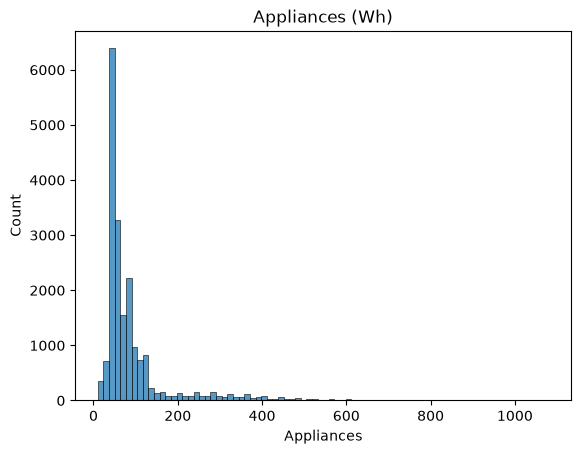

In [ ]:
sns.histplot(df["Appliances"], bins=80); plt.title("Appliances (Wh)"); plt.show()

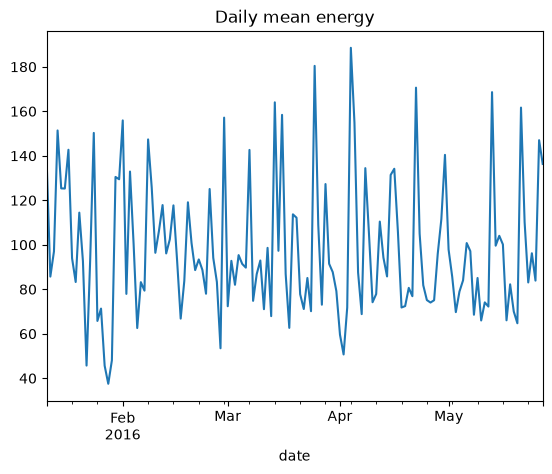

In [20]:
df.set_index("date")["Appliances"].resample("D").mean().plot(title="Daily mean energy"); plt.show()

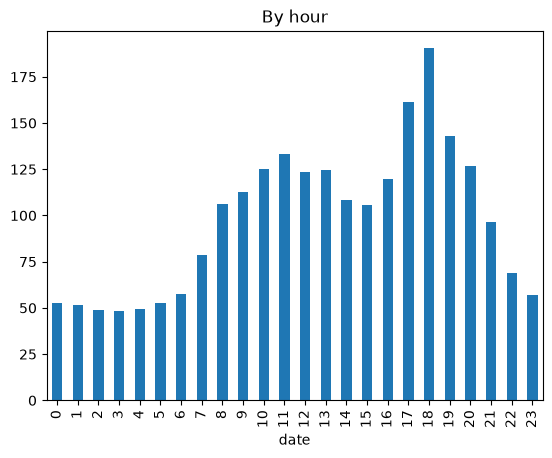

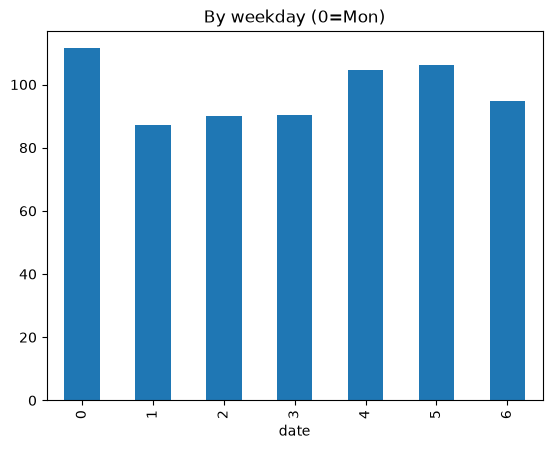

In [21]:
df.groupby(df["date"].dt.hour)["Appliances"].mean().plot(kind="bar", title="By hour"); plt.show()
df.groupby(df["date"].dt.dayofweek)["Appliances"].mean().plot(kind="bar", title="By weekday (0=Mon)"); plt.show()

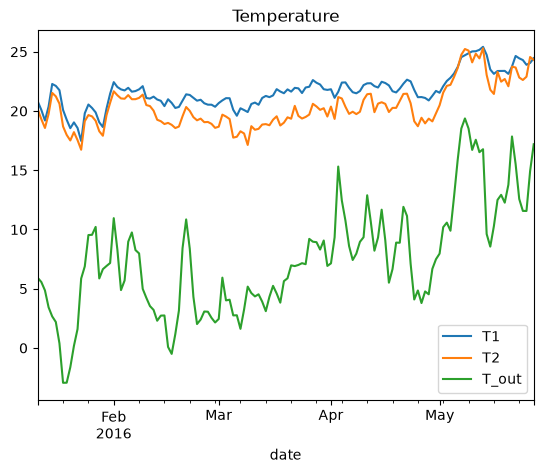

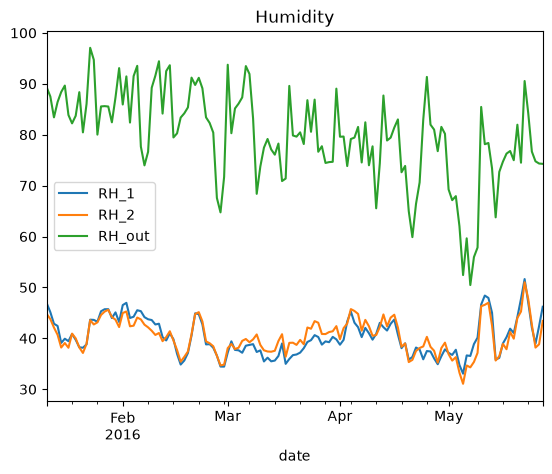

In [22]:
df.set_index("date")[["T1","T2","T_out"]].resample("D").mean().plot(title="Temperature"); plt.show()
df.set_index("date")[["RH_1","RH_2","RH_out"]].resample("D").mean().plot(title="Humidity"); plt.show()

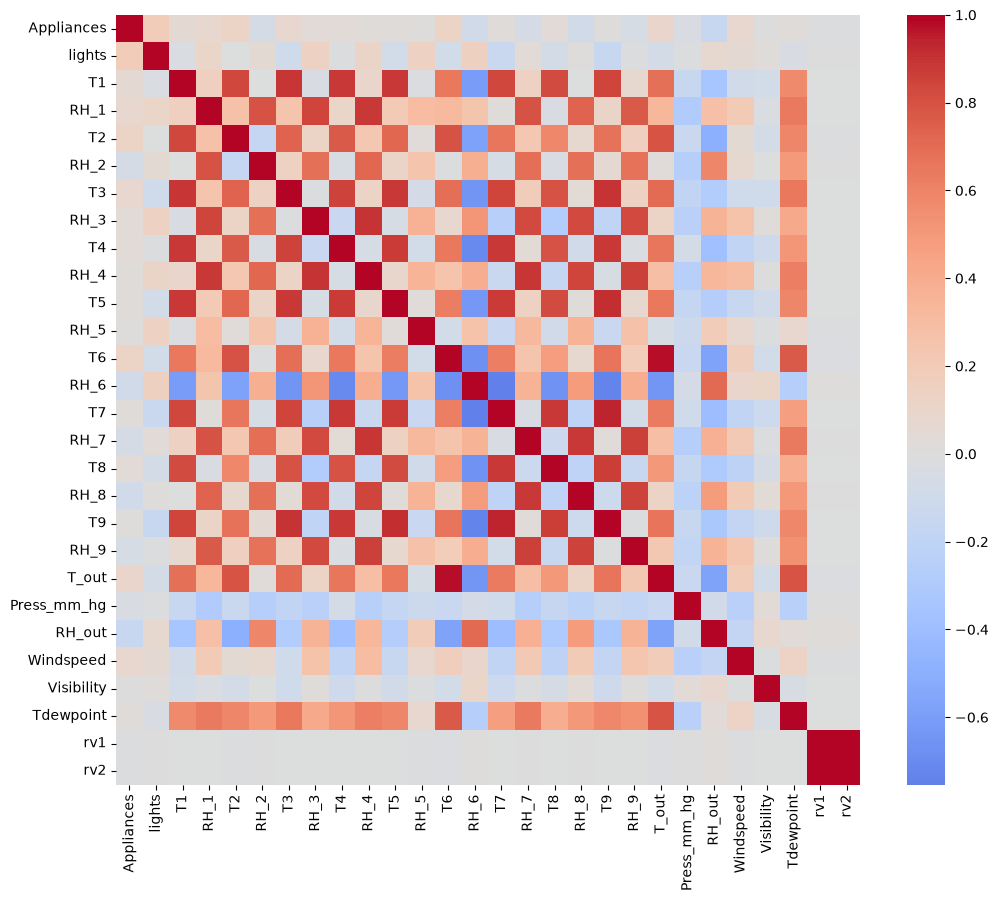

In [23]:
plt.figure(figsize=(12,10))
sns.heatmap(df.drop(columns="date").corr(), cmap="coolwarm", center=0); plt.show()